# Figure 3 · drug-gene interaction

AUROC / AUPRC of drug -> gene and gene -> drug prediction on the test pairs (5 seeds each), from the published
scores:

* `SNN+{vision_scores,gene,text,all}`: the DGI classifier on VISION signatures or on PertOmni embeddings
  (expression, text, both);
* `PertOmni+{gene,text,all}`: cosine similarity of the pretrained PertOmni embeddings (no training on interactions);
* `PertOmni_ft+text`: PertOmni with text encoders fine-tuned on the training interactions;
* red dashed line: Tahoe blog (VISION signature similarity); gray dashed line (AUPRC): fraction of positive pairs.

All methods are in one plot per task and score. Runs: package README, sections 3 and 5. New runs: `scores.pkl` of
`scripts/evaluate_dgi.py` has the same `{use_emb: {metric: [per seed]}}` layout, that of
`scripts/baselines/tahoe_blog.py` the `{metric: value}` layout of `tahoe_scores.pkl`.

In [1]:
import warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings("ignore")  # deprecation notices of the installed libraries
from pertomni import paths      # pip install -e . in the repository root
from pertomni.io import load_obj, save_obj

R = paths.DATA                  # published inputs and results (data/, or $PERTOMNI_DATA)
FIG = Path("figures")           # figures of this notebook, next to it
FIG.mkdir(exist_ok=True)
SEEDS = range(5)
# editable text in PDF / SVG (TrueType fonts, <text> elements)
plt.rcParams.update({"pdf.fonttype": 42, "ps.fonttype": 42, "svg.fonttype": "none"})

In [2]:
from pertomni.data.dgi import RETRIEVAL_DIRS
TASKS = {"drug2gene": "test_drug_gene_pairs.pkl", "gene2drug": "test_drug_gene_pairs_new.pkl"}  # task: published test pair file

def task_dir(task):
    """Pair folder of a DGI task (RETRIEVAL_DIRS); the published drug -> gene pairs and scores are in
    drug_target_retrieval_new/."""
    path = R / RETRIEVAL_DIRS[task]
    legacy = path.with_name(path.name + "_new")
    return legacy if not path.exists() and legacy.exists() else path

In [3]:
BASE = "bothmask_concat_pathway_shared_text_es_acc"
FT = {"drug2gene": f"ft_text_drug_new_target_{BASE}", "gene2drug": f"ft_text_gene_target_{BASE}"}  # published model names
HUE = {"SNN": "#1f77b4", "PertOmni": "#ff7f0e", "PertOmni_ft": "#2ca02c"}  # seaborn default slots, as in the paper
METRICS = ["auroc", "auprc", "weighted_recall", "weighted_f1"]

def load_scores(task):
    d = task_dir(task) / "retrieval_results"
    snn, ft, blog = load_obj(d / "snn_scores.pkl")["es_loss"], load_obj(d / "ft_scores.pkl"), load_obj(d / "tahoe_scores.pkl")
    rows = []
    for use_emb, per_metric in snn.items():
        rows += [dict(method=f"SNN+{use_emb}", base="SNN", metric=m, seed=s, value=v) for m in METRICS for s, v in enumerate(per_metric[m])]
    for model, base, embs in ((BASE, "PertOmni", ["gene", "text", "all"]), (FT[task], "PertOmni_ft", ["text"])):
        for use_emb in embs:
            rows += [dict(method=f"{base}+{use_emb}", base=base, metric=m, seed=s, value=v) for m in METRICS for s, v in enumerate(ft[model][use_emb][m])]
    pairs = load_obj(task_dir(task) / TASKS[task])
    positive_rate = sum(p[2] for p in pairs) / len(pairs)
    return pd.DataFrame(rows), blog, positive_rate

DATA = {task: load_scores(task) for task in TASKS}
pd.concat({task: df.groupby(["method", "metric"])["value"].mean().unstack() for task, (df, _, _) in DATA.items()}).round(4)

metric                        auprc   auroc  weighted_f1  weighted_recall
          method                                                         
drug2gene PertOmni+all       0.0001  0.4060       0.3929           0.2619
          PertOmni+gene      0.0001  0.4389       0.6914           0.5894
          PertOmni+text      0.0001  0.4357       0.6168           0.4528
          PertOmni_ft+text   0.0001  0.6426       0.8250           0.7277
          SNN+all            0.0001  0.5363       0.6261           0.5258
          SNN+gene           0.0001  0.6058       0.7536           0.6152
          SNN+text           0.0001  0.6107       0.8501           0.7415
          SNN+vision_scores  0.0001  0.4863       0.6964           0.5446
gene2drug PertOmni+all       0.0001  0.4733       0.3572           0.2305
          PertOmni+gene      0.0001  0.4541       0.3439           0.2449
          PertOmni+text      0.0001  0.4961       0.3072           0.1845
          PertOmni_ft+text   0.0002  0.6945       0.8759           0.7967
          SNN+all            0.0001  0.5610       0.7095           0.5564
          SNN+gene           0.0001  0.4851       0.4510           0.3130
          SNN+text           0.0001  0.6175       0.6647           0.4994
          SNN+vision_scores  0.0001  0.4854       0.7453           0.6193

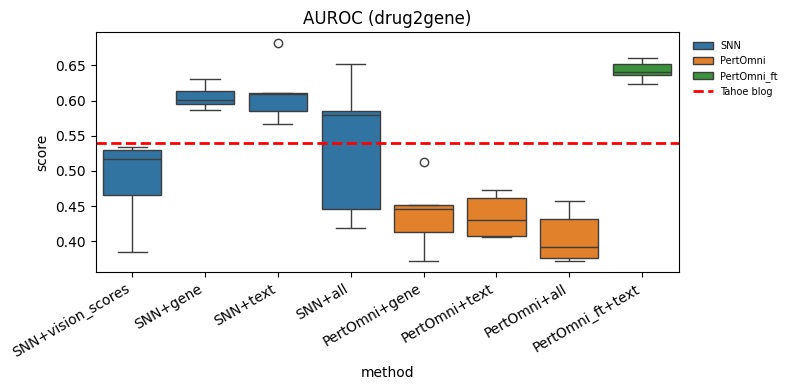

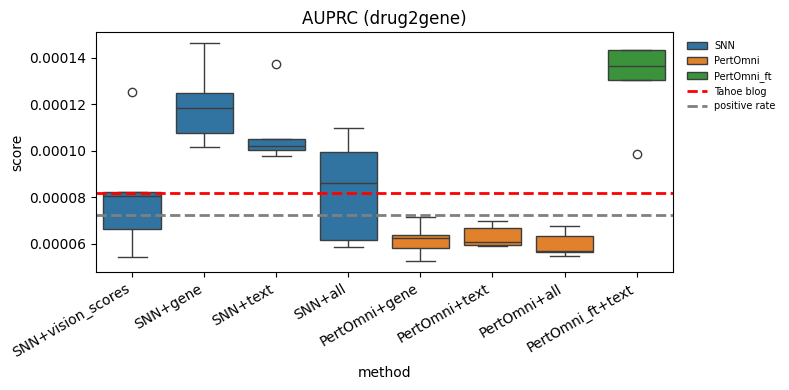

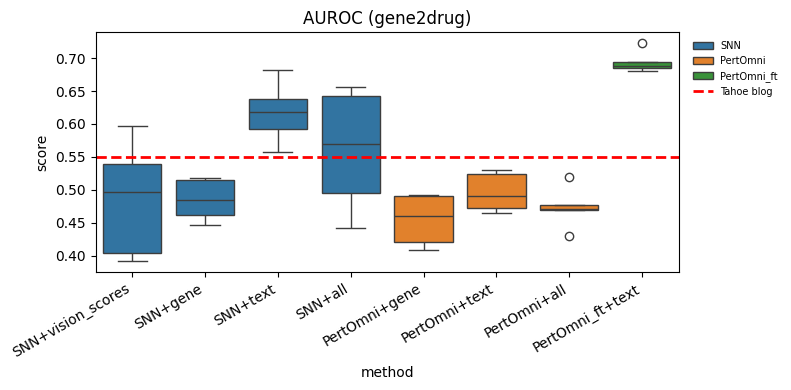

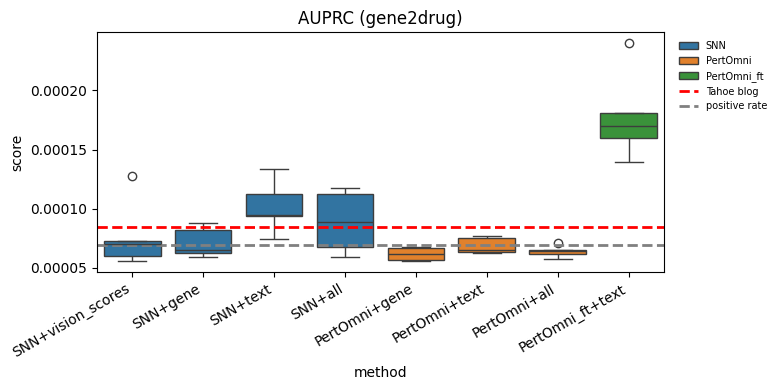

In [4]:
# the paper splits these into the main figure (SNN, PertOmni_ft) and the supplement (zero-shot PertOmni)
ORDER = ["SNN+vision_scores", "SNN+gene", "SNN+text", "SNN+all", "PertOmni+gene", "PertOmni+text", "PertOmni+all", "PertOmni_ft+text"]

def plot(task, metric):
    df, blog, positive_rate = DATA[task]
    d = df[df["metric"] == metric]
    fig, ax = plt.subplots(figsize=(8, 4))
    sns.boxplot(data=d, x="method", y="value", hue="base", order=ORDER, palette=HUE, dodge=False, ax=ax)
    ax.axhline(blog[metric], color="red", ls="--", lw=2, label="Tahoe blog")
    if metric == "auprc":
        ax.axhline(positive_rate, color="grey", ls="--", lw=2, label="positive rate")
    ax.set_title(f"{metric.upper()} ({task})")
    ax.set_xlabel("method")
    ax.set_ylabel("score")
    ax.tick_params(axis="x", rotation=30)
    for t in ax.get_xticklabels():
        t.set_ha("right")
    ax.legend(fontsize=7, frameon=False, loc="upper left", bbox_to_anchor=(1.01, 1))
    fig.tight_layout()
    fig.savefig(FIG / f"{task}_{metric}.pdf")
    plt.show()

for task in TASKS:
    for metric in ["auroc", "auprc"]:
        plot(task, metric)